# Description d'un dataset — `NOM_DU_DATASET`

**Projet :** _ · **Auteur :** _ · **Relecteur :** _ · **Date :** _

## Chargement par echantillonnage

DAF+ 97 fichiers

In [5]:
#Effectis et quotas proportionnels pour les fichiers DVF+ (sans charger les CSV en mémoire)
from pathlib import Path
import pandas as pd
import numpy as np

dossier = Path("/home/naude/formation/projet_compagnon/data/DVF+")
fichiers = sorted(dossier.glob("dvf_plus_d*.csv"))

# Compter les lignes sans charger les CSV en mémoire
effectifs = {}

for fichier in fichiers:
    with open(fichier, "rb") as f:
        effectifs[fichier.name] = sum(1 for _ in f) - 1

repartition = pd.DataFrame.from_dict(
    effectifs,
    orient="index",
    columns=["Effectif"]
)

total = repartition["Effectif"].sum()
objectif = 100_000

# Calculer les proportions
repartition["Proportion (%)"] = (
    repartition["Effectif"] / total * 100
).round(3)

# Calculer les quotas et ajuster les arrondis
quotas_exacts = repartition["Effectif"] / total * objectif

repartition["Quota"] = np.floor(quotas_exacts).astype(int)

reste = objectif - repartition["Quota"].sum()

indices = (
    (quotas_exacts - repartition["Quota"])
    .sort_values(ascending=False)
    .head(reste)
    .index
)

repartition.loc[indices, "Quota"] += 1

display(repartition.sort_values("Effectif", ascending=False))

print("Total des lignes sources :", total)
print("Total des quotas :", repartition["Quota"].sum())

,Effectif,Proportion (%),Quota
dvf_plus_d59.csv,533889,3.223,3223
dvf_plus_d75.csv,498059,3.007,3007
dvf_plus_d13.csv,470197,2.838,2839
dvf_plus_d33.csv,465409,2.810,2810
dvf_plus_d69.csv,435142,2.627,2627
...,...,...,...
dvf_plus_d971.csv,41072,0.248,248
dvf_plus_d972.csv,34700,0.209,209
dvf_plus_d90.csv,28767,0.174,174
dvf_plus_d48.csv,24793,0.150,150


Total des lignes sources : 16565022
Total des quotas : 100000


In [6]:
sortie = dossier.parent / "dvf_plus_echantillon_100k.csv"
rng = np.random.default_rng(42)

premier_bloc = True
total_extrait = 0
colonnes_reference = None

for fichier in fichiers:
    n_total = int(repartition.loc[fichier.name, "Effectif"])
    quota = int(repartition.loc[fichier.name, "Quota"])

    # Tirer les positions aléatoires sans remise
    positions = np.sort(
        rng.choice(n_total, size=quota, replace=False)
    )

    debut = 0

    for bloc in pd.read_csv(
        fichier,
        sep="|",
        chunksize=10_000,
        low_memory=False
    ):
        # Vérifier que les colonnes sont identiques
        if colonnes_reference is None:
            colonnes_reference = bloc.columns.tolist()
        elif bloc.columns.tolist() != colonnes_reference:
            raise ValueError(
                f"Colonnes différentes dans {fichier.name}"
            )

        fin = debut + len(bloc)

        indices = positions[
            (positions >= debut) & (positions < fin)
        ] - debut

        if len(indices) > 0:
            extrait = bloc.iloc[indices].copy()

            extrait["departement_source"] = (
                fichier.stem.removeprefix("dvf_plus_d")
            )

            extrait.to_csv(
                sortie,
                mode="w" if premier_bloc else "a",
                header=premier_bloc,
                index=False,
                sep="|"
            )

            premier_bloc = False
            total_extrait += len(extrait)

        debut = fin

    if debut != n_total:
        raise ValueError(
            f"Nombre de lignes incohérent dans {fichier.name}"
        )

    print(f"{fichier.name} : {quota} lignes extraites")

print("\nTotal extrait :", total_extrait)
print("Fichier créé :", sortie)

dvf_plus_d01.csv : 1026 lignes extraites
dvf_plus_d02.csv : 694 lignes extraites
dvf_plus_d03.csv : 560 lignes extraites
dvf_plus_d04.csv : 317 lignes extraites
dvf_plus_d05.csv : 386 lignes extraites
dvf_plus_d06.csv : 2478 lignes extraites
dvf_plus_d07.csv : 585 lignes extraites
dvf_plus_d08.csv : 383 lignes extraites
dvf_plus_d09.csv : 334 lignes extraites
dvf_plus_d10.csv : 498 lignes extraites
dvf_plus_d11.csv : 890 lignes extraites
dvf_plus_d12.csv : 531 lignes extraites
dvf_plus_d13.csv : 2839 lignes extraites
dvf_plus_d14.csv : 1308 lignes extraites
dvf_plus_d15.csv : 259 lignes extraites
dvf_plus_d16.csv : 663 lignes extraites
dvf_plus_d17.csv : 1576 lignes extraites
dvf_plus_d18.csv : 489 lignes extraites
dvf_plus_d19.csv : 439 lignes extraites
dvf_plus_d21.csv : 959 lignes extraites
dvf_plus_d22.csv : 1172 lignes extraites
dvf_plus_d23.csv : 298 lignes extraites
dvf_plus_d24.csv : 840 lignes extraites
dvf_plus_d25.csv : 829 lignes extraites
dvf_plus_d26.csv : 827 lignes extr

In [4]:
import pandas as pd
import numpy as np
df=pd.read_csv('/home/naude/formation/projet_compagnon/data/dvf_plus_echantillon_100k.csv', sep="|", low_memory=False)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)

# 0. Rôle du dataset dans le projet

## 1. Situer la source et ouvrir les données



**Objectif :** pouvoir expliquer en deux minutes à quoi sert cette base dans le projet. Se remplit à la fin, une fois les étapes faites.

# A. Identité

## 1. Source et origine

**Objectif :** savoir d'où vient la donnée et comment elle est produite, pour juger sa fiabilité.



**Constat :**

Les données DVF (Demandes de valeurs foncières) sont produites par la Direction générale des Finances publiques (DGFiP) à partir de sources fiscales, notamment FIDJI et MAJIC.
Le modèle DVF+, développé par le Cerema, restructure ces données en plusieurs tables et ajoute des variables calculées ou agrégées pour faciliter leur exploitation. La table mutation correspond aux mutations immobilières.
Les données DVF sont d'origine administrative, et non issues d'annonces immobilières ou de scraping. 


**Documentation** : guide Cerema De DVF à DV3F, dont la dernière mise à jour de fond est indiquée comme juin 2021. Le PDF a été généré le 10 octobre 2026. Une documentation technique en ligne existe et peut évoluer indépendamment de ce PDF. 
 

**Impact projet :**
DVF+ constitue une source pertinente pour étudier les transactions immobilières effectivement enregistrées. Elle ne décrit cependant pas l'intégralité du marché : certaines mutations sont exclues, et les caractéristiques des biens restent limitées, notamment si nous utilisons uniquement la table mutation. 


**Points de vigiliances :**
Le document distingue trois modèles : DVF brut, DVF+ et DV3F. Nous travaillons sur DVF+ et non sur DV3F qui n'est pas en opensource. 

## 2. Dimensions, unité d'observations

**Objectif :** connaître le volume (effectifs, mémoire, temps de calcul), savoir ce que représente une ligne.


In [6]:
print(df.shape)
print(df.info())
display(df.head())

(100000, 64)
<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 64 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   idmutation          100000 non-null  int64  
 1   idmutinvar          100000 non-null  str    
 2   idopendata          100000 non-null  str    
 3   idnatmut            100000 non-null  int64  
 4   codservch           0 non-null       float64
 5   refdoc              0 non-null       float64
 6   datemut             100000 non-null  str    
 7   anneemut            100000 non-null  int64  
 8   moismut             100000 non-null  int64  
 9   coddep              100000 non-null  str    
 10  libnatmut           100000 non-null  str    
 11  nbartcgi            100000 non-null  int64  
 12  l_artcgi            0 non-null       float64
 13  vefa                100000 non-null  bool   
 14  valeurfonc          99810 non-null   float64
 15  nbdispo             100000 non-nu

,idmutation,idmutinvar,idopendata,idnatmut,codservch,refdoc,datemut,anneemut,moismut,coddep,libnatmut,nbartcgi,l_artcgi,vefa,valeurfonc,nbdispo,nblot,nbcomm,l_codinsee,nbsection,l_section,nbpar,l_idpar,nbparmut,l_idparmut,nbsuf,sterr,l_dcnt,nbvolmut,nblocmut,l_idlocmut,nblocmai,nblocapt,nblocdep,nblocact,nbapt1pp,nbapt2pp,nbapt3pp,nbapt4pp,nbapt5pp,nbmai1pp,nbmai2pp,nbmai3pp,nbmai4pp,nbmai5pp,sbati,sbatmai,sbatapt,sbatact,sapt1pp,sapt2pp,sapt3pp,sapt4pp,sapt5pp,smai1pp,smai2pp,smai3pp,smai4pp,smai5pp,codtypbien,libtypbien,geompar_x,geompar_y,departement_source
0,64165,4a4f7722c4faa20d42bdbcb4eecfbd09,4a4f7722c4faa20d42bdbcb4eecfbd09,1,NaN,NaN,2014-08-13,2014,8,1,Vente,0,NaN,False,70000.0,1,3.0,1,01093,1,0C,1,010930000C1713,0,NaN,0,0.0,"0,0,0,0,0,0,0,0,0,0,0,0,0",0,2,"010930000025060_0,010930000025061_0",0,1,1,0,0,1,0,0,0,0,0,0,0,0,57.0,0.0,57.0,0.0,0.0,57.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,121,UN APPARTEMENT,851462.366122,6.559607e+06,01
1,80412,46e7aad1fdf644f37c2c4fdca2db2099,46e7aad1fdf644f37c2c4fdca2db2099,1,NaN,NaN,2014-07-24,2014,7,1,Vente,0,NaN,False,175833.0,1,3.0,1,01053,1,AC,1,01053000AC0528,0,NaN,0,0.0,"0,0,0,0,0,0,0,0,0,0,0,0,0",0,2,"010530000003995_0,010530000003996_0",0,1,1,0,0,0,1,0,0,0,0,0,0,0,68.0,0.0,68.0,0.0,0.0,0.0,68.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,121,UN APPARTEMENT,871670.083169,6.570332e+06,01
2,85035,4c577daa8d735d583c62b975f4a5aab9,4c577daa8d735d583c62b975f4a5aab9,1,NaN,NaN,2014-12-17,2014,12,1,Vente,0,NaN,False,170000.0,1,0.0,1,01202,1,0I,2,"012020000I0090,012020000I0091",2,"012020000I0090,012020000I0091",4,1813.0,"583.0000000000000000,0.0000000000000000,0.0000...",0,1,012020000020539_0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,88.0,88.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,88.0,111,UNE MAISON,881714.192722,6.537775e+06,01
3,93068,3a368a3c7a63b6a8b390e1923c72d4e9,3a368a3c7a63b6a8b390e1923c72d4e9,1,NaN,NaN,2014-10-17,2014,10,1,Vente,0,NaN,False,156000.0,1,0.0,1,01351,1,0A,5,"013510000A0799,013510000A0800,013510000A0801,0...",5,"013510000A0799,013510000A0800,013510000A0801,0...",5,25860.0,"3458.0000000000000000,19962.0000000000000000,0...",0,2,"013510000026163_0,013510000026164_0",2,0,0,0,0,0,0,0,0,2,0,0,0,0,120.0,120.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,120.0,0.0,0.0,0.0,0.0,112,DES MAISONS,843659.837524,6.563588e+06,01
4,87405,3f6174680abd4a87de18944ab1952f05,3f6174680abd4a87de18944ab1952f05,6,NaN,NaN,2014-11-04,2014,11,1,Echange,0,NaN,False,3240.0,1,0.0,1,01248,1,ZL,1,01248000ZL0012,1,01248000ZL0012,1,8310.0,"8310.0000000000000000,0.0000000000000000,0.000...",0,0,NaN,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2313,TERRAIN DE TYPE TERRE ET PRE,846505.392457,6.535030e+06,01


In [ ]:
#Vérification de l'unicité des identifiants de mutation
df["idmutation"].nunique()

100000

## 3. Temporalité

In [21]:
# Bornes temporelles observées
print("Première date :", df["datemut"].min())
print("Dernière date :", df["datemut"].max())

# Répartition des mutations par année
print("\nMutations par année :")
print(df["anneemut"].value_counts().sort_index())

Première date : 2014-01-02
Dernière date : 2025-12-31

Mutations par année :
anneemut
2014     6460
2015     7079
2016     7479
2017     8661
2018     8627
2019     9325
2020     8636
2021    10329
2022    10281
2023     8041
2024     7290
2025     7792
Name: count, dtype: int64


**Constat :** 

Le dataset analysé est un **échantillon de 100 000 observations et 64 colonnes**, occupant environ **48,2 Mo en mémoire**.

Il a été constitué à partir de 97 fichiers départementaux DVF+, couvrant la période 2014–2025. L'échantillonnage a été réalisé de manière **aléatoire stratifiée proportionnelle par département**, avec une graine fixée à 42 pour assurer la reproductibilité du tirage.

Les 64 colonnes comprennent 63 variables issues de la table `mutation` de DVF+ et une variable ajoutée lors de l'échantillonnage, `departement_source`, permettant de conserver l'origine départementale des observations.

Les variables présentent différents types (`int64`, `float64`, `str`, `bool`) et certaines comportent des valeurs manquantes.

**Unité d'observation :** une ligne correspond à une mutation immobilière, c'est-à-dire une opération de transfert de propriété pouvant concerner un ou plusieurs biens.

Contrairement aux fichiers DVF bruts, où une mutation peut apparaître sur plusieurs lignes, la table mutation de DVF+ présente un enregistrement par mutation.

La vérification de idmutation confirme la présence de 100 000 identifiants uniques pour 100 000 observations. Chaque ligne représente donc une mutation distincte dans l'échantillon.

**Limite :** les 100 000 observations ne constituent pas la base nationale exhaustive. La stratification proportionnelle vise à préserver le poids relatif des départements dans les fichiers sources, mais ne garantit pas à elle seule la représentativité de toutes les caractéristiques des transactions.
Par ailleurs, les informations agrégées à l'échelle d'une mutation ne permettent pas nécessairement de caractériser individuellement chaque bien vendu. 
Toutefois, les données DVF brutes présentent également une limite importante : bien qu'elles permettent d'identifier les différents locaux et parcelles concernés par une mutation, la valeur foncière est renseignée pour l'ensemble de la transaction et non pour chaque bien. Ainsi, lorsqu'une mutation comprend plusieurs biens, il est possible de les dénombrer et de décrire certaines de leurs caractéristiques, mais pas d'attribuer un prix de vente individuel à chacun.

Le choix entre DVF brut et la table mutation de DVF+ implique donc un compromis entre le niveau de détail des biens et la facilité d'analyse des transactions.

# B. Variables

## 3. Dictionnaire des variables

**Objectif :** inventaire complet : nom, signification, type, unité.



**Variables de type str (selon la documentation)**

| Variable | Libellé / Signification | Type Pandas | Type statistique |
|---|---|---|---|
| `idmutinvar` | Identifiant invariant de la mutation | `str` | Identifiant |
| `idopendata` | Identifiant de la mutation dans les données ouvertes | `str` | Identifiant |
| `datemut` | Date de la mutation | `str` | Temporelle |
| `coddep` | Code du département | `str` | Qualitative nominale |
| `libnatmut` | Libellé de la nature de la mutation (vente, échange, VEFA, etc.) | `str` | Qualitative nominale |
| `l_codinsee` | Liste des codes INSEE des communes concernées | `str` | Liste de codes géographiques |
| `l_section` | Liste des sections cadastrales concernées | `str` | Liste de références cadastrales |
| `l_idpar` | Liste des identifiants des parcelles concernées | `str` | Liste d'identifiants |
| `l_idparmut` | Liste des identifiants des parcelles ayant muté | `str` | Liste d'identifiants |
| `l_dcnt` | Liste des surfaces de terrain ayant muté, par catégorie d'occupation du sol | `str` | Liste de valeurs quantitatives |
| `l_idlocmut` | Liste des identifiants des locaux ayant muté | `str` | Liste d'identifiants |
| `libtypbien` | Libellé du type de biens concernés par la mutation | `str` | Qualitative nominale |
| `departement_source` | Département du fichier source utilisé pour l'échantillonnage | `str` | Qualitative nominale |


In [13]:
#Vérification des variables de type str selon indications de la documentation DVF+
for col in ['coddep', 'libnatmut', 'libtypbien', 'departement_source']:
    print(f"\nVariable : {col}")
    print(df[col].value_counts())


Variable : coddep
coddep
59     3223
75     3007
13     2839
33     2810
69     2627
       ... 
971     248
972     209
90      174
48      150
973     123
Name: count, Length: 97, dtype: int64

Variable : libnatmut
libnatmut
Vente                                 92043
Vente en l'état futur d'achèvement     6522
Echange                                 736
Vente terrain à bâtir                   415
Adjudication                            281
Expropriation                             3
Name: count, dtype: int64

Variable : libtypbien
libtypbien
UNE MAISON                                   34244
UN APPARTEMENT                               27853
TERRAIN DE TYPE TERRE ET PRE                  7213
TERRAIN DE TYPE TAB                           4558
ACTIVITE                                      3703
BATI - INDETERMINE : Vefa sans descriptif     3538
UNE DEPENDANCE                                3276
TERRAIN ARTIFICIALISE MIXTE                   2817
TERRAIN FORESTIER                       

**Variable de type bolléenne (selon la documentation)**

| Variable | Libellé / Signification | Type Pandas | Type statistique |
|---|---|---|---|
| `vefa` | Vente en l'état futur d'achèvement (vente sur plan). Indique si la mutation concerne une VEFA (`True`) ou non (`False`). | `bool` | Qualitative nominale binaire |


In [15]:
df['vefa'].value_counts()

vefa
False    93478
True      6522
Name: count, dtype: int64

**Variables numériques (selon la documentation)**

| Variable | Libellé / Signification | Type Pandas | Nature statistique |
|---|---|---|---|
| `idmutation` | Identifiant unique de la mutation | `int64` | Identifiant |
| `idnatmut` | Code de la nature de mutation | `int64` | Qualitative nominale codée |
| `codservch` | Code du service chargé de l'enregistrement | `float64` | Qualitative nominale codée |
| `refdoc` | Référence du document fiscal | `float64` | Identifiant / référence |
| `anneemut` | Année de la mutation | `int64` | Temporelle discrète |
| `moismut` | Mois de la mutation (1 à 12) | `int64` | Temporelle discrète |
| `nbartcgi` | Nombre d'articles du Code général des impôts associés à la mutation | `int64` | Quantitative discrète |
| `l_artcgi` | Liste des articles du Code général des impôts associés à la mutation | `float64` | Liste de codes (non numérique au sens statistique) |
| `valeurfonc` | Valeur foncière totale de la mutation, en euros | `float64` | Quantitative continue |
| `nbdispo` | Nombre de dispositions associées à la mutation | `int64` | Quantitative discrète |
| `nblot` | Nombre de lots concernés par la mutation | `float64` | Quantitative discrète |
| `nbcomm` | Nombre de communes concernées | `int64` | Quantitative discrète |
| `nbsection` | Nombre de sections cadastrales concernées | `int64` | Quantitative discrète |
| `nbpar` | Nombre de parcelles concernées | `int64` | Quantitative discrète |
| `nbparmut` | Nombre de parcelles ayant effectivement muté | `int64` | Quantitative discrète |
| `nbsuf` | Nombre de subdivisions fiscales concernées | `int64` | Quantitative discrète |
| `sterr` | Surface totale de terrain associée à la mutation, en m² | `float64` | Quantitative continue |
| `nbvolmut` | Nombre de volumes immobiliers ayant muté | `int64` | Quantitative discrète |
| `nblocmut` | Nombre de locaux ayant muté | `int64` | Quantitative discrète |
| `nblocmai` | Nombre de maisons concernées | `int64` | Quantitative discrète |
| `nblocapt` | Nombre d'appartements concernés | `int64` | Quantitative discrète |
| `nblocdep` | Nombre de dépendances concernées | `int64` | Quantitative discrète |
| `nblocact` | Nombre de locaux d'activité concernés | `int64` | Quantitative discrète |
| `nbapt1pp` | Nombre d'appartements de 1 pièce principale | `int64` | Quantitative discrète |
| `nbapt2pp` | Nombre d'appartements de 2 pièces principales | `int64` | Quantitative discrète |
| `nbapt3pp` | Nombre d'appartements de 3 pièces principales | `int64` | Quantitative discrète |
| `nbapt4pp` | Nombre d'appartements de 4 pièces principales | `int64` | Quantitative discrète |
| `nbapt5pp` | Nombre d'appartements de 5 pièces principales ou plus | `int64` | Quantitative discrète |
| `nbmai1pp` | Nombre de maisons de 1 pièce principale | `int64` | Quantitative discrète |
| `nbmai2pp` | Nombre de maisons de 2 pièces principales | `int64` | Quantitative discrète |
| `nbmai3pp` | Nombre de maisons de 3 pièces principales | `int64` | Quantitative discrète |
| `nbmai4pp` | Nombre de maisons de 4 pièces principales | `int64` | Quantitative discrète |
| `nbmai5pp` | Nombre de maisons de 5 pièces principales ou plus | `int64` | Quantitative discrète |
| `sbati` | Surface bâtie totale associée à la mutation, en m² | `float64` | Quantitative continue |
| `sbatmai` | Surface bâtie totale des maisons, en m² | `float64` | Quantitative continue |
| `sbatapt` | Surface bâtie totale des appartements, en m² | `float64` | Quantitative continue |
| `sbatact` | Surface bâtie totale des locaux d'activité, en m² | `float64` | Quantitative continue |
| `sapt1pp` | Surface totale des appartements de 1 pièce principale, en m² | `float64` | Quantitative continue |
| `sapt2pp` | Surface totale des appartements de 2 pièces principales, en m² | `float64` | Quantitative continue |
| `sapt3pp` | Surface totale des appartements de 3 pièces principales, en m² | `float64` | Quantitative continue |
| `sapt4pp` | Surface totale des appartements de 4 pièces principales, en m² | `float64` | Quantitative continue |
| `sapt5pp` | Surface totale des appartements de 5 pièces principales ou plus, en m² | `float64` | Quantitative continue |
| `smai1pp` | Surface totale des maisons de 1 pièce principale, en m² | `float64` | Quantitative continue |
| `smai2pp` | Surface totale des maisons de 2 pièces principales, en m² | `float64` | Quantitative continue |
| `smai3pp` | Surface totale des maisons de 3 pièces principales, en m² | `float64` | Quantitative continue |
| `smai4pp` | Surface totale des maisons de 4 pièces principales, en m² | `float64` | Quantitative continue |
| `smai5pp` | Surface totale des maisons de 5 pièces principales ou plus, en m² | `float64` | Quantitative continue |
| `codtypbien` | Code de la typologie des biens concernés par la mutation | `int64` | Qualitative nominale codée |
| `geompar_x` | Coordonnée X de localisation géographique de la mutation | `float64` | Coordonnée géographique |
| `geompar_y` | Coordonnée Y de localisation géographique de la mutation | `float64` | Coordonnée géographique |



In [16]:
# 1. Variables qualitatives textuelles
df_str_cat = df[['coddep', 'libnatmut', 'libtypbien']].copy()

# 2. Variable qualitative booléenne
df_cat = df[['vefa']].copy()

# 3. Variables quantitatives discrètes (dénombrements)
df_num_discrete = df[[
    'nbartcgi', 'nbdispo', 'nblot', 'nbcomm',
    'nbsection', 'nbpar', 'nbparmut', 'nbsuf',
    'nbvolmut', 'nblocmut', 'nblocmai', 'nblocapt',
    'nblocdep', 'nblocact',
    'nbapt1pp', 'nbapt2pp', 'nbapt3pp', 'nbapt4pp', 'nbapt5pp',
    'nbmai1pp', 'nbmai2pp', 'nbmai3pp', 'nbmai4pp', 'nbmai5pp'
]].copy()

# 4. Variables quantitatives continues (valeurs et surfaces)
df_num_quanti = df[[
    'valeurfonc', 'sterr', 'sbati', 'sbatmai', 'sbatapt', 'sbatact',
    'sapt1pp', 'sapt2pp', 'sapt3pp', 'sapt4pp', 'sapt5pp',
    'smai1pp', 'smai2pp', 'smai3pp', 'smai4pp', 'smai5pp'
]].copy()


print("Qualitatives textuelles :", df_str_cat.shape)
print("Qualitative booléenne   :", df_cat.shape)
print("Quantitatives discrètes :", df_num_discrete.shape)
print("Quantitatives continues :", df_num_quanti.shape)

Qualitatives textuelles : (100000, 3)
Qualitative booléenne   : (100000, 1)
Quantitatives discrètes : (100000, 24)
Quantitatives continues : (100000, 16)


In [17]:
for col in df_num_discrete :
    print(f"\nVariable : {col}")
    print(df[col].value_counts())


Variable : nbartcgi
nbartcgi
0    100000
Name: count, dtype: int64

Variable : nbdispo
nbdispo
1     98470
2      1409
3        83
4        16
5        12
6         5
8         2
21        1
37        1
10        1
Name: count, dtype: int64

Variable : nblot
nblot
0.0      60578
2.0      16445
1.0      11606
3.0       8463
4.0       1786
         ...  
61.0         1
45.0         1
130.0        1
138.0        1
75.0         1
Name: count, Length: 66, dtype: int64

Variable : nbcomm
nbcomm
1     98823
2      1052
3        94
4        19
5         6
6         3
9         1
7         1
10        1
Name: count, dtype: int64

Variable : nbsection
nbsection
1     96559
2      2646
3       475
4       159
5        74
6        30
7        21
8        14
10        7
9         5
11        3
12        2
13        2
19        1
14        1
15        1
Name: count, dtype: int64

Variable : nbpar
nbpar
1      74854
2      12804
3       5006
4       2549
5       1409
       ...  
57         1
226   

In [19]:
df_num_quanti.describe().T

,count,mean,std,min,25%,50%,75%,max
valeurfonc,99810.0,231662.523061,2.354898e+06,0.0,58000.0,140000.0,240000.0,606210300.0
sterr,100000.0,4551.320560,5.848486e+04,0.0,0.0,268.0,1079.0,10786128.0
sbati,100000.0,96.182800,7.425770e+02,0.0,0.0,60.0,95.0,91435.0
sbatmai,100000.0,38.853640,6.692633e+01,0.0,0.0,0.0,81.0,7699.0
sbatapt,100000.0,23.579210,3.112282e+02,0.0,0.0,0.0,36.0,77643.0
sbatact,100000.0,33.748830,6.704959e+02,0.0,0.0,0.0,0.0,91435.0
sapt1pp,100000.0,2.300280,2.365603e+01,0.0,0.0,0.0,0.0,3819.0
sapt2pp,100000.0,5.352210,5.098174e+01,0.0,0.0,0.0,0.0,12547.0
sapt3pp,100000.0,8.136470,1.377568e+02,0.0,0.0,0.0,0.0,38620.0
sapt4pp,100000.0,5.545910,1.066654e+02,0.0,0.0,0.0,0.0,23899.0




### 3.1. Variables qualitatives et booléennes

**Constats**

L'échantillon couvre **97 départements**, avec des effectifs variables selon les territoires. Cette répartition résulte de l'échantillonnage aléatoire stratifié proportionnel réalisé sur les fichiers départementaux.

Les mutations sont très majoritairement des **ventes classiques (92,04 %)**, suivies des ventes en l'état futur d'achèvement (**VEFA : 6,52 %**). Les échanges, adjudications, ventes de terrains à bâtir et expropriations représentent ensemble environ 1,44 % des observations.

La variable booléenne `vefa` présente 6 522 valeurs `True`, soit exactement le nombre de mutations de catégorie « Vente en l'état futur d'achèvement ».

La typologie des biens est plus diversifiée :

- `UNE MAISON` : 34 244 mutations (34,24 %).
- `UN APPARTEMENT` : 27 853 mutations (27,85 %).
- Les autres catégories regroupent notamment les terrains, locaux d'activité, dépendances, mutations portant sur plusieurs biens et biens indéterminés.

Les catégories `UNE MAISON` et `UN APPARTEMENT` totalisent **62 097 observations, soit 62,10 % de l'échantillon**.

**Limites**

La base regroupe des opérations immobilières de natures très différentes, qui ne correspondent pas toutes au marché résidentiel ciblé par Compagnon Immo.

Par ailleurs, 3 538 mutations sont classées `BATI - INDETERMINE : Vefa sans descriptif`. Ces observations soulèvent la question de la disponibilité des caractéristiques nécessaires à une estimation immobilière.

**Décisions envisagées**

Le futur modèle pourrait être centré sur les ventes d'une maison ou d'un appartement individuel, à destination des particuliers et professionnels d'agence immobilière.

Les VEFA restent à étudier séparément avant de décider de leur inclusion, compte tenu des différences entre les marchés du neuf et de l'ancien et des descriptions parfois insuffisantes.

Cette orientation constitue une **hypothèse de périmètre métier**, pas encore une règle de sélection définitive.

### 3.2. Variables quantitatives discrètes

**Constats**

La plupart des mutations présentent une structure relativement simple :

- 98,47 % concernent une seule disposition (`nbdispo = 1`).
- 98,82 % concernent une seule commune (`nbcomm = 1`).
- 96,56 % concernent une seule section cadastrale (`nbsection = 1`).
- 74,85 % concernent une seule parcelle (`nbpar = 1`).

Le nombre de locaux varie davantage :

- 24,82 % des mutations ne comportent aucun local ayant muté.
- 43,77 % comportent un seul local.
- 20,15 % comportent deux locaux.
- Les autres mutations concernent trois locaux ou davantage.

Les dénombrements par catégorie montrent également des opérations immobilières de grande ampleur, avec des valeurs maximales observées de **71 maisons, 1 630 appartements et 619 dépendances** dans certaines mutations.

Les variables décrivant les logements selon leur nombre de pièces présentent une forte concentration sur zéro, ce qui est attendu puisqu'elles concernent des types de biens particuliers.

Enfin, `nbartcgi` vaut systématiquement zéro dans l'échantillon. Cette variable n'apporte donc aucune variabilité descriptive.

**Limites**

Une mutation comprenant plusieurs locaux ne correspond pas nécessairement à une vente de plusieurs logements : les locaux peuvent notamment inclure des dépendances.

De même, plusieurs parcelles ou plusieurs lots ne signifient pas nécessairement plusieurs logements vendus.

Les valeurs extrêmes des dénombrements témoignent de la présence d'opérations complexes, très différentes des transactions résidentielles individuelles recherchées.

Enfin, certains zéros peuvent correspondre à l'absence réelle d'un type de bien plutôt qu'à une information manquante.

**Décisions envisagées**

Pour le futur modèle, privilégier les mutations portant sur **un seul logement identifiable**, tout en examinant la présence éventuelle de dépendances.

Les critères de sélection devront s'appuyer conjointement sur `libtypbien`, `nblocmai`, `nblocapt`, `nblocmut` et éventuellement `nblocdep`, plutôt que sur le seul nombre de lots ou de parcelles.

`nbartcgi` pourra être considéré comme non informatif dans cet échantillon, sans qu'aucune suppression soit effectuée pendant l'audit.

### 3.3. Variables quantitatives continues

**Constats**

La variable `valeurfonc` est renseignée pour 99 810 mutations sur 100 000, soit **99,81 % de complétude**.

Sa distribution est fortement asymétrique :

| Indicateur | Valeur foncière |
|---|---:|
| Moyenne | 231 663 € |
| Médiane | 140 000 € |
| Premier quartile | 58 000 € |
| Troisième quartile | 240 000 € |
| Minimum | 0 € |
| Maximum | 606 210 300 € |

La moyenne dépasse nettement la médiane et l'écart-type atteint environ 2,35 millions d'euros, indiquant une forte dispersion et l'influence de transactions de très grande valeur.

Les variables de surface présentent également des distributions très asymétriques.

La surface bâtie totale `sbati` possède une médiane de 60 m², une moyenne de 96,18 m² et un maximum de 91 435 m².

La surface de terrain `sterr` présente une médiane de 268 m², une moyenne de 4 551 m² et un maximum de 10 786 128 m².

Les surfaces détaillées par type de logement et nombre de pièces ont généralement une médiane nulle. Cela reflète notamment le fait qu'une mutation ne concerne pas simultanément toutes les catégories de biens.

**Limites**

Les moyennes calculées sur l'ensemble des mutations sont peu représentatives d'une transaction résidentielle individuelle, puisqu'elles mélangent logements, terrains, activités et opérations complexes.

Les valeurs extrêmes ne constituent pas nécessairement des erreurs : elles peuvent correspondre à des ventes portant sur de nombreux biens ou sur des surfaces importantes.

Les valeurs foncières nulles devront être examinées pour déterminer leur signification. De même, une surface égale à zéro ne doit pas être systématiquement interprétée comme une anomalie ou une absence de renseignement.

La valeur foncière correspond à la mutation entière, ce qui rend son interprétation délicate lorsqu'elle porte sur plusieurs biens.

**Décisions envisagées**

Ne pas définir de seuil de suppression des valeurs extrêmes à partir de ces seules statistiques descriptives.

Approfondir ultérieurement l'étude de `valeurfonc` et des surfaces sur la population résidentielle retenue, afin de distinguer les valeurs plausibles, les situations particulières et les éventuelles anomalies.

La pertinence des indicateurs statistiques devra être réévaluée après définition du périmètre métier.

### 3.4. Synthèse et implications pour Compagnon Immo

L'audit descriptif révèle une forte hétérogénéité des mutations immobilières. La base regroupe des ventes résidentielles individuelles, des terrains, des locaux professionnels et des transactions complexes pouvant porter sur plusieurs dizaines, voire centaines de biens.

Ces situations extrêmes influencent fortement les distributions et rendent les statistiques globales peu pertinentes pour évaluer la qualité des données destinées au futur modèle.

Décision : procéder dès maintenant à un sous-échantillonnage métier, afin de poursuivre l'audit sur une population plus homogène et cohérente avec les utilisateurs ciblés : particuliers et professionnels d'agence immobilière.

Le périmètre envisagé est le suivant :

Mutations de nature Vente ou Vente en l'état futur d'achèvement.

Typologie UNE MAISON ou UN APPARTEMENT.

Transaction portant sur un seul logement, avec possibilité de dépendances associées.

Les VEFA dépourvues de descriptif exploitable ne seront pas intégrées à ce premier périmètre.

La base initiale de 100 000 mutations sera conservée intacte. Le sous-échantillon constituera une nouvelle population d'étude, sur laquelle seront poursuivies les vérifications de qualité : valeurs manquantes, cohérence des surfaces, valeurs foncières atypiques et distributions géographiques et temporelles.

La constitution éventuelle d'un nouvel échantillon de 200 000 mutations sera réévaluée après mesure du nombre d'observations conservées.

Cette démarche permet de distinguer les caractéristiques normales de transactions complexes des véritables problèmes de qualité des données dans le périmètre métier retenu.

In [34]:
#Réalisation d'un sous échantillon résidentiel à partir de l'échantillon initial de 100 000 lignes
# Nature des transactions retenues
nature_ok = df["libnatmut"].isin([
    "Vente",
    "Vente en l'état futur d'achèvement"
])

# Une seule maison, aucun appartement ni local d'activité
maison_ok = (
    (df["libtypbien"] == "UNE MAISON")
    & (df["nblocmai"] == 1)
    & (df["nblocapt"] == 0)
    & (df["nblocact"] == 0)
)

# Un seul appartement, aucune maison ni local d'activité
appartement_ok = (
    (df["libtypbien"] == "UN APPARTEMENT")
    & (df["nblocapt"] == 1)
    & (df["nblocmai"] == 0)
    & (df["nblocact"] == 0)
)

# Sous-échantillon résidentiel
df_residentiel = df.loc[
    nature_ok & (maison_ok | appartement_ok)
].copy()

print("Dimensions :", df_residentiel.shape)
print("Part de l'échantillon initial :",
      round(len(df_residentiel) / len(df) * 100, 2), "%")



# 1. Variables qualitatives textuelles
df_str_cat = df_residentiel[[
    'coddep', 'libnatmut', 'libtypbien'
]].copy()

# 2. Variable qualitative booléenne
df_cat = df_residentiel[['vefa']].copy()

# 3. Variables quantitatives discrètes (dénombrements)
df_num_discrete = df_residentiel[[
    'nbartcgi', 'nbdispo', 'nblot', 'nbcomm',
    'nbsection', 'nbpar', 'nbparmut', 'nbsuf',
    'nbvolmut', 'nblocmut', 'nblocmai', 'nblocapt',
    'nblocdep', 'nblocact',
    'nbapt1pp', 'nbapt2pp', 'nbapt3pp', 'nbapt4pp', 'nbapt5pp',
    'nbmai1pp', 'nbmai2pp', 'nbmai3pp', 'nbmai4pp', 'nbmai5pp'
]].copy()

# 4. Variables quantitatives continues (valeurs et surfaces)
df_num_quanti = df_residentiel[[
    'valeurfonc', 'sterr', 'sbati', 'sbatmai', 'sbatapt', 'sbatact',
    'sapt1pp', 'sapt2pp', 'sapt3pp', 'sapt4pp', 'sapt5pp',
    'smai1pp', 'smai2pp', 'smai3pp', 'smai4pp', 'smai5pp'
]].copy()

# Vérification
print("Qualitatives textuelles :", df_str_cat.shape)
print("Qualitative booléenne   :", df_cat.shape)
print("Quantitatives discrètes :", df_num_discrete.shape)
print("Quantitatives continues :", df_num_quanti.shape)

Dimensions : (61834, 64)
Part de l'échantillon initial : 61.83 %
Qualitatives textuelles : (61834, 3)
Qualitative booléenne   : (61834, 1)
Quantitatives discrètes : (61834, 24)
Quantitatives continues : (61834, 16)


# C. Qualité

## 4. Doublons 

**Objectif :** repérer les lignes copiées, qui gonflent les effectifs.


In [25]:
# Nombre de lignes strictement identiques
df_residentiel.duplicated().sum()

np.int64(0)

In [26]:
# Nombre de répétitions de l'identifiant
df_residentiel.duplicated(subset=["idmutation"]).sum()

np.int64(0)

In [27]:
print("Doublons exacts :", df_residentiel.duplicated().sum())
print("Doublons idmutation :", df_residentiel.duplicated(subset=["idmutation"]).sum())

Doublons exacts : 0
Doublons idmutation : 0


## 5. Valeurs manquantes 

**Objectif :** mesurer l'ampleur des manquants par variable.




In [28]:
#Vérification des quantité de valeur manquante dans le dataset
missing = (df_residentiel.isna().mean() * 100).round(2)
missing = missing[missing > 0].sort_values(ascending=False)

display(missing)

codservch     100.00
refdoc        100.00
l_artcgi      100.00
l_idparmut     46.43
geompar_x       0.35
geompar_y       0.35
valeurfonc      0.03
dtype: float64

In [31]:
display(pd.crosstab(
    df_residentiel["nbparmut"] == 0,
    df_residentiel["l_idparmut"].isna(),
    margins=True
)
)
print("Les 46,43 % de valeurs manquantes de l_idparmut correspondent exclusivement aux mutations pour lesquelles nbparmut = 0.")

l_idparmut,False,True,All
nbparmut,,,
False,33122,0,33122
True,0,28712,28712
All,33122,28712,61834


Les 46,43 % de valeurs manquantes de l_idparmut correspondent exclusivement aux mutations pour lesquelles nbparmut = 0.


## 6 Distributions et valeurs extrêmes


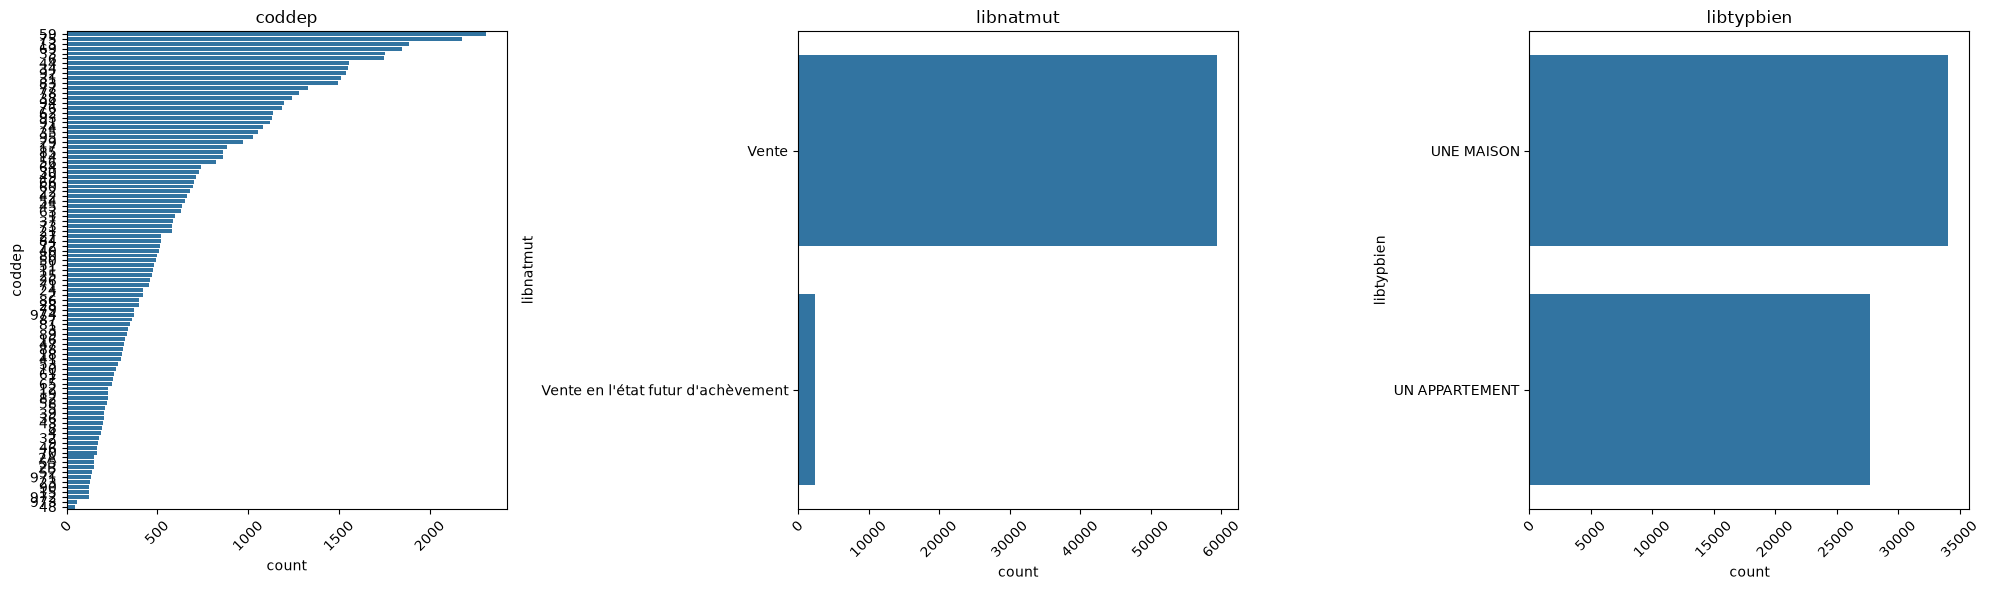

In [35]:
import matplotlib.pyplot as plt
import seaborn as sns
#Visualisation des variables catégorielles
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
axes = axes.flatten()

for i, col in enumerate(df_str_cat.columns[:3]):
    sns.countplot(
        data=df_str_cat,
        y=col,
        order=df_str_cat[col].value_counts().index,
        ax=axes[i]
    )
    axes[i].set_title(col)
    axes[i].tick_params(axis="x", rotation=45)

# Masquer les emplacements inutilisés
for ax in axes[len(df_str_cat.columns[:3]):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

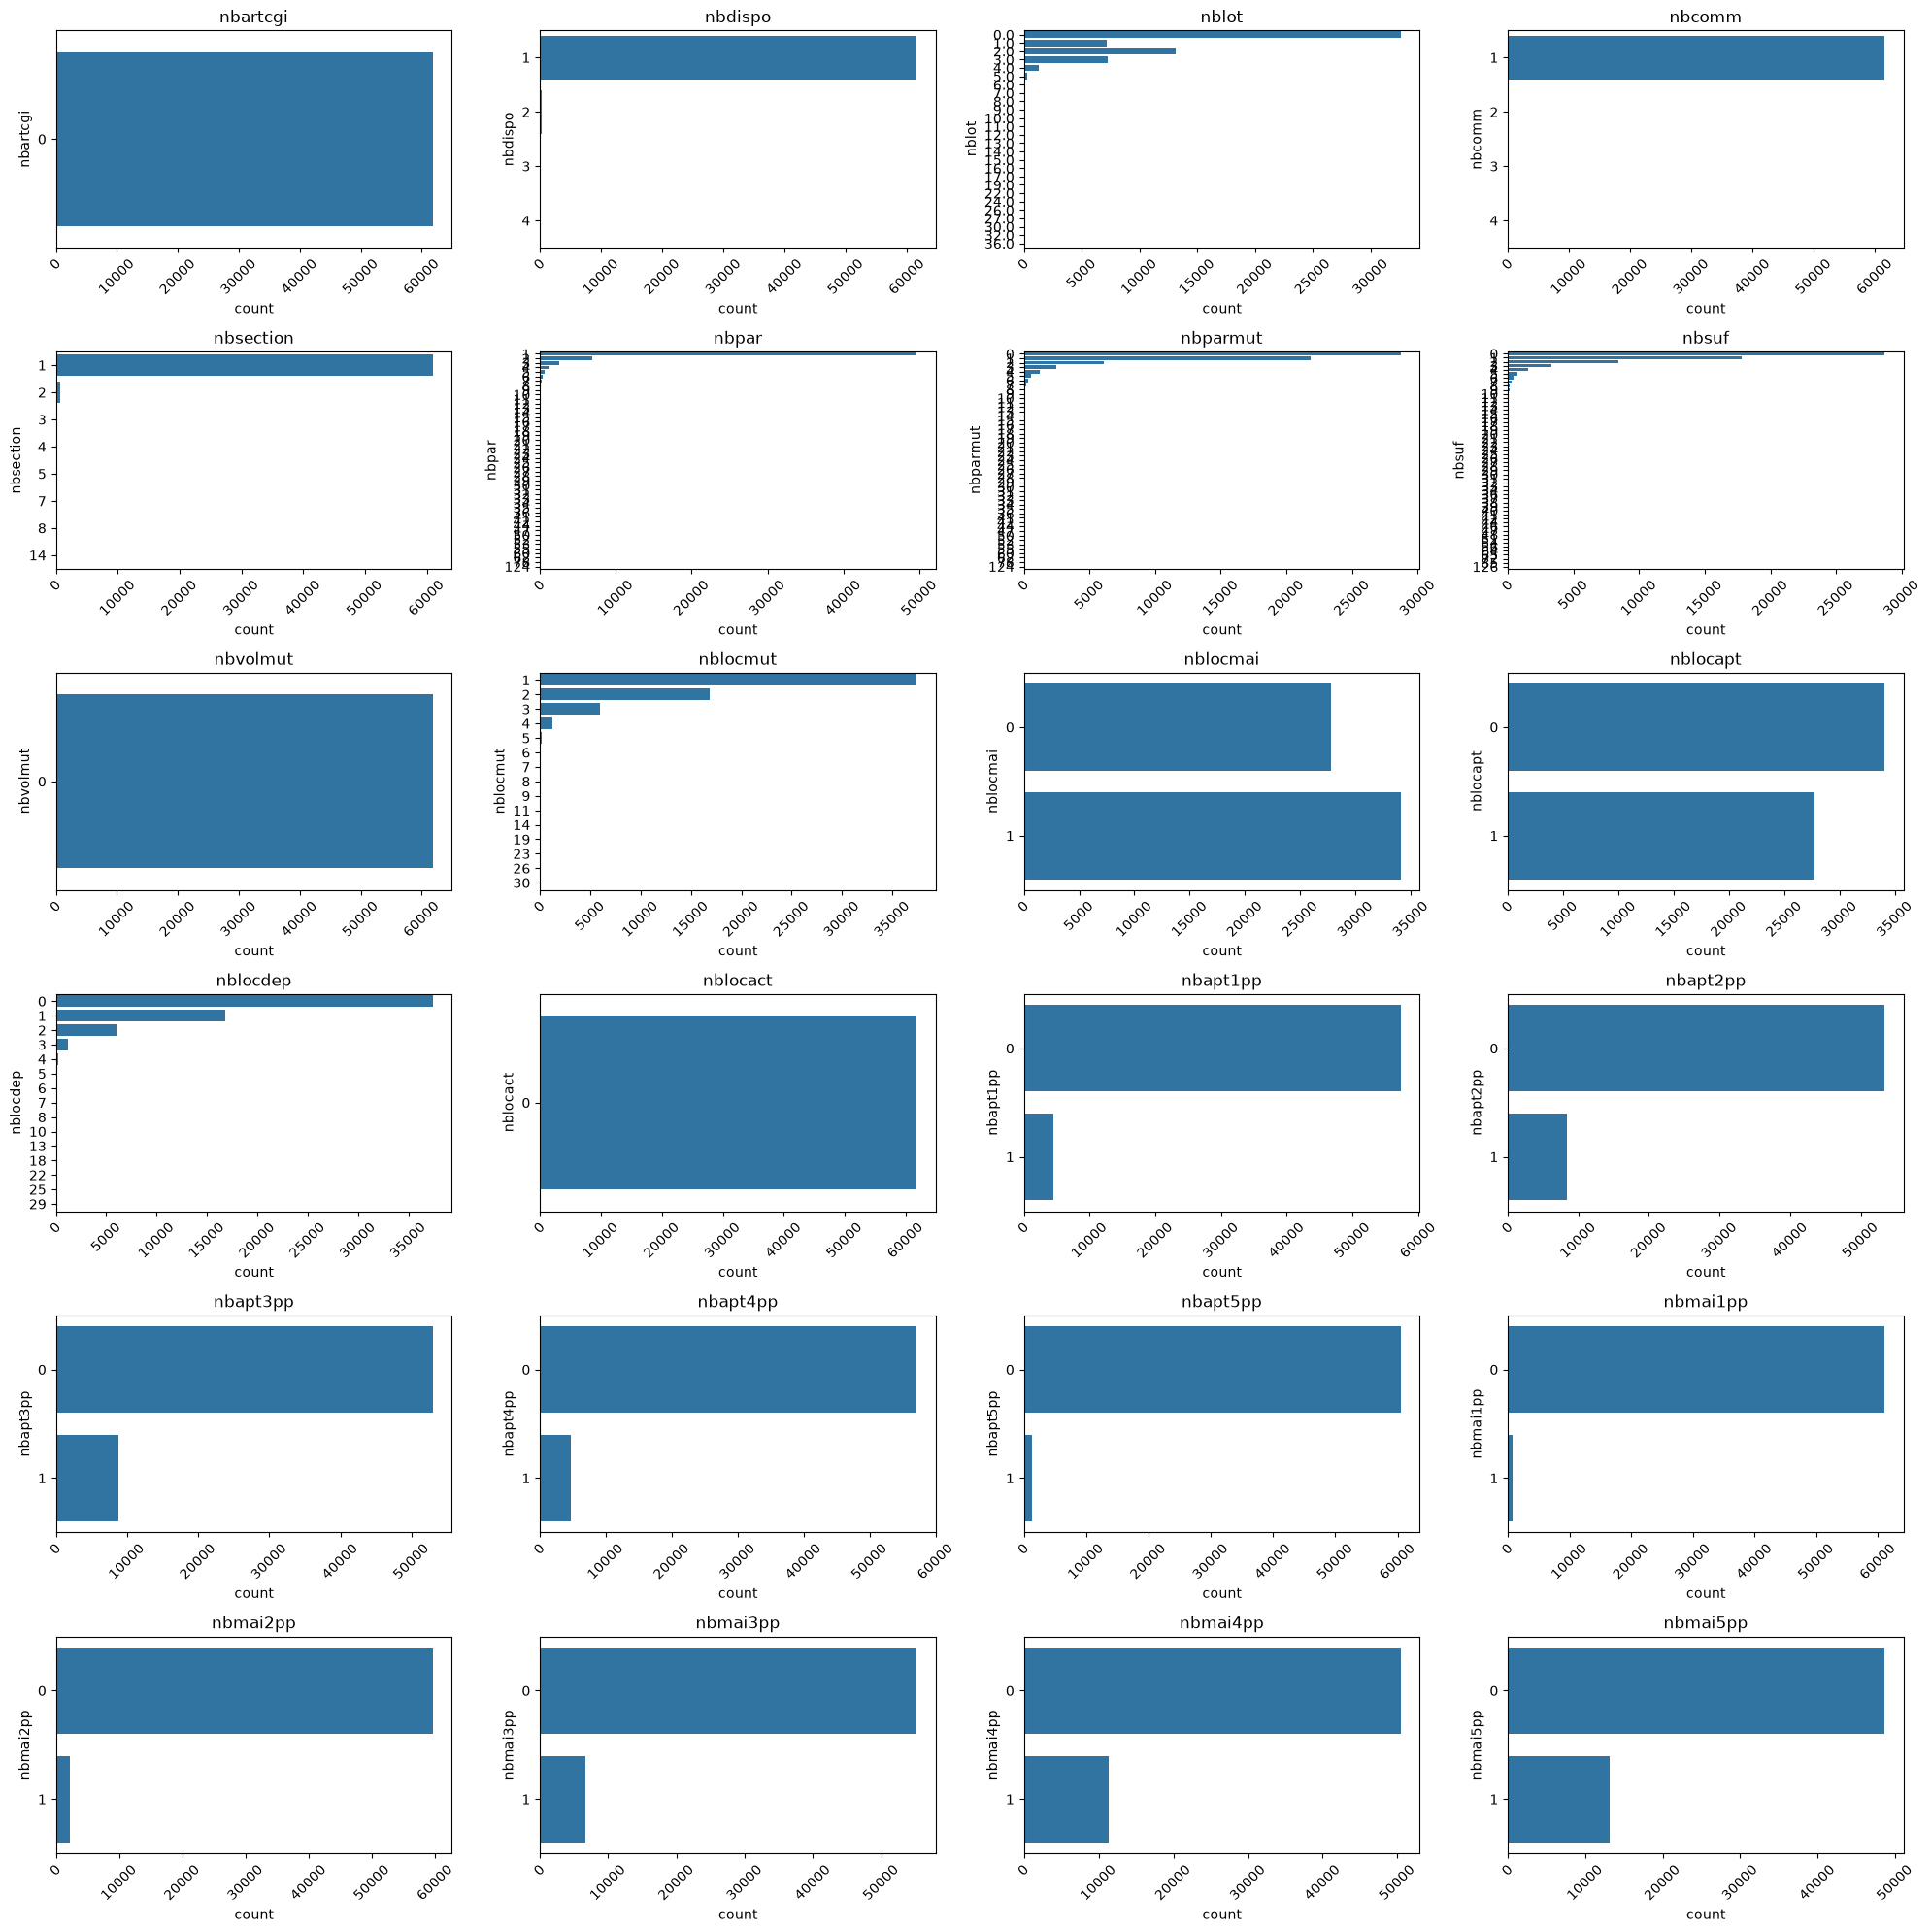

In [38]:
#Visualisation des variables quantitatives discrètes
# Visualisation des variables quantitatives discrètes
fig, axes = plt.subplots(6, 4, figsize=(20, 20))
axes = axes.flatten()

for i, col in enumerate(df_num_discrete.columns):
    sns.countplot(
        data=df_num_discrete,
        y=col,
        order=df_num_discrete[col].value_counts().sort_index().index,
        ax=axes[i]
    )
    axes[i].set_title(col)
    axes[i].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

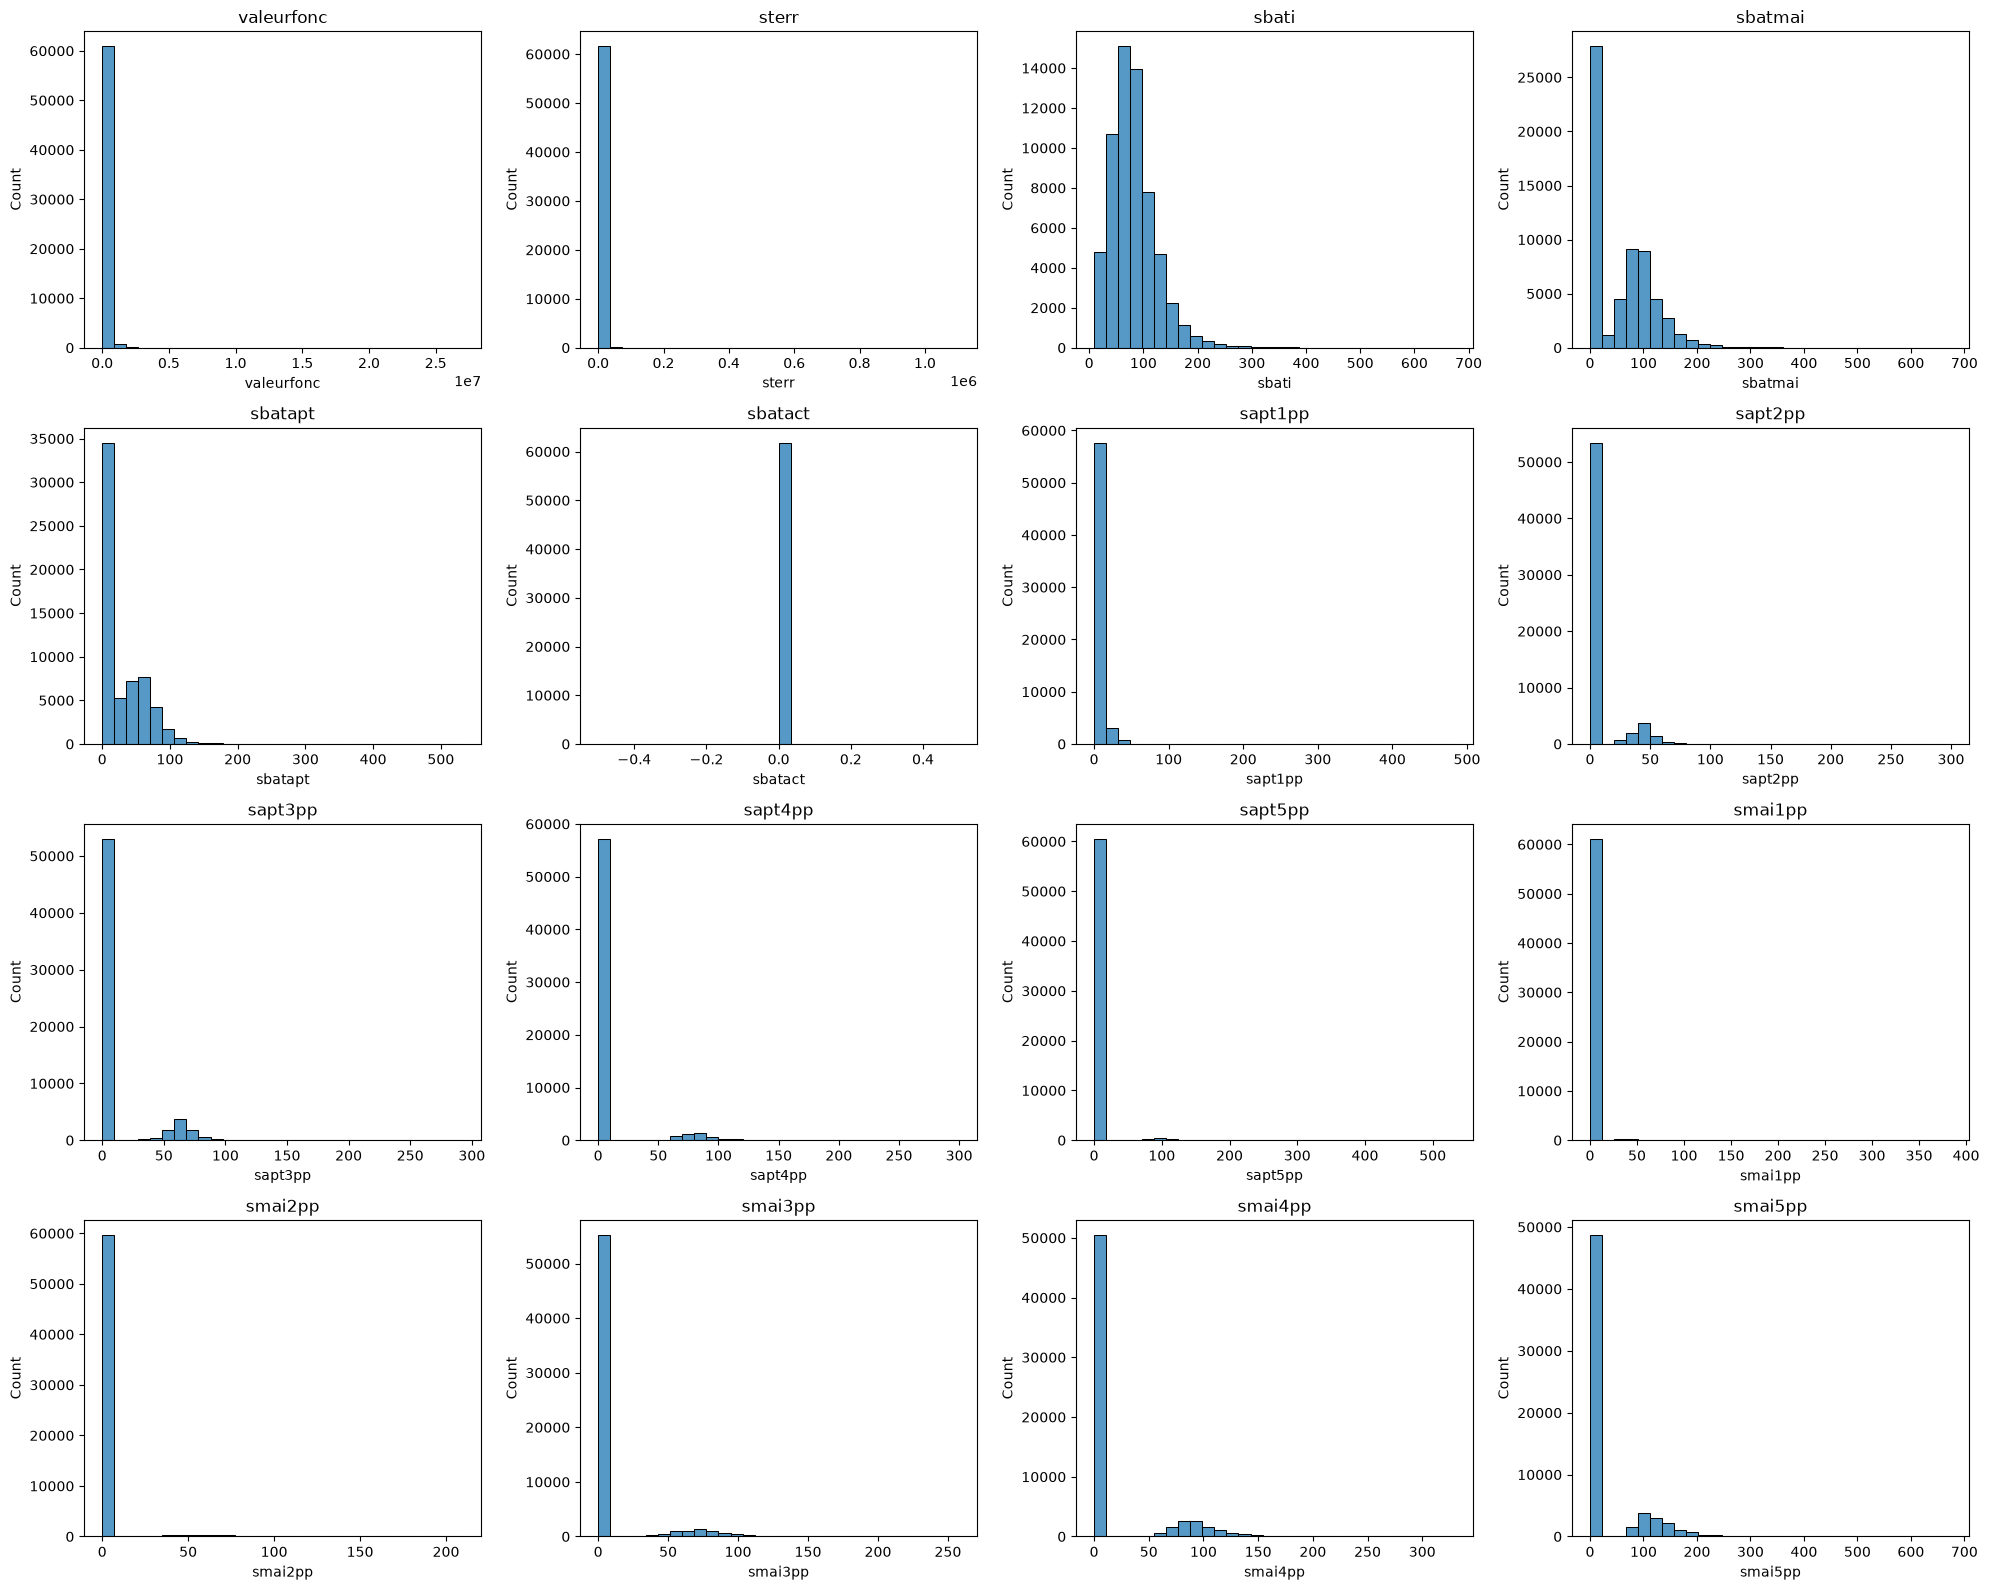

In [41]:
# Visualisation des variables quantitatives continues
fig, axes = plt.subplots(4, 4, figsize=(20, 16))
axes = axes.flatten()

for i, col in enumerate(df_num_quanti.columns):
    sns.histplot(
        data=df_num_quanti,
        x=col,
        bins=30,
        ax=axes[i]
    )
    axes[i].set_title(col)

plt.tight_layout()
plt.show()

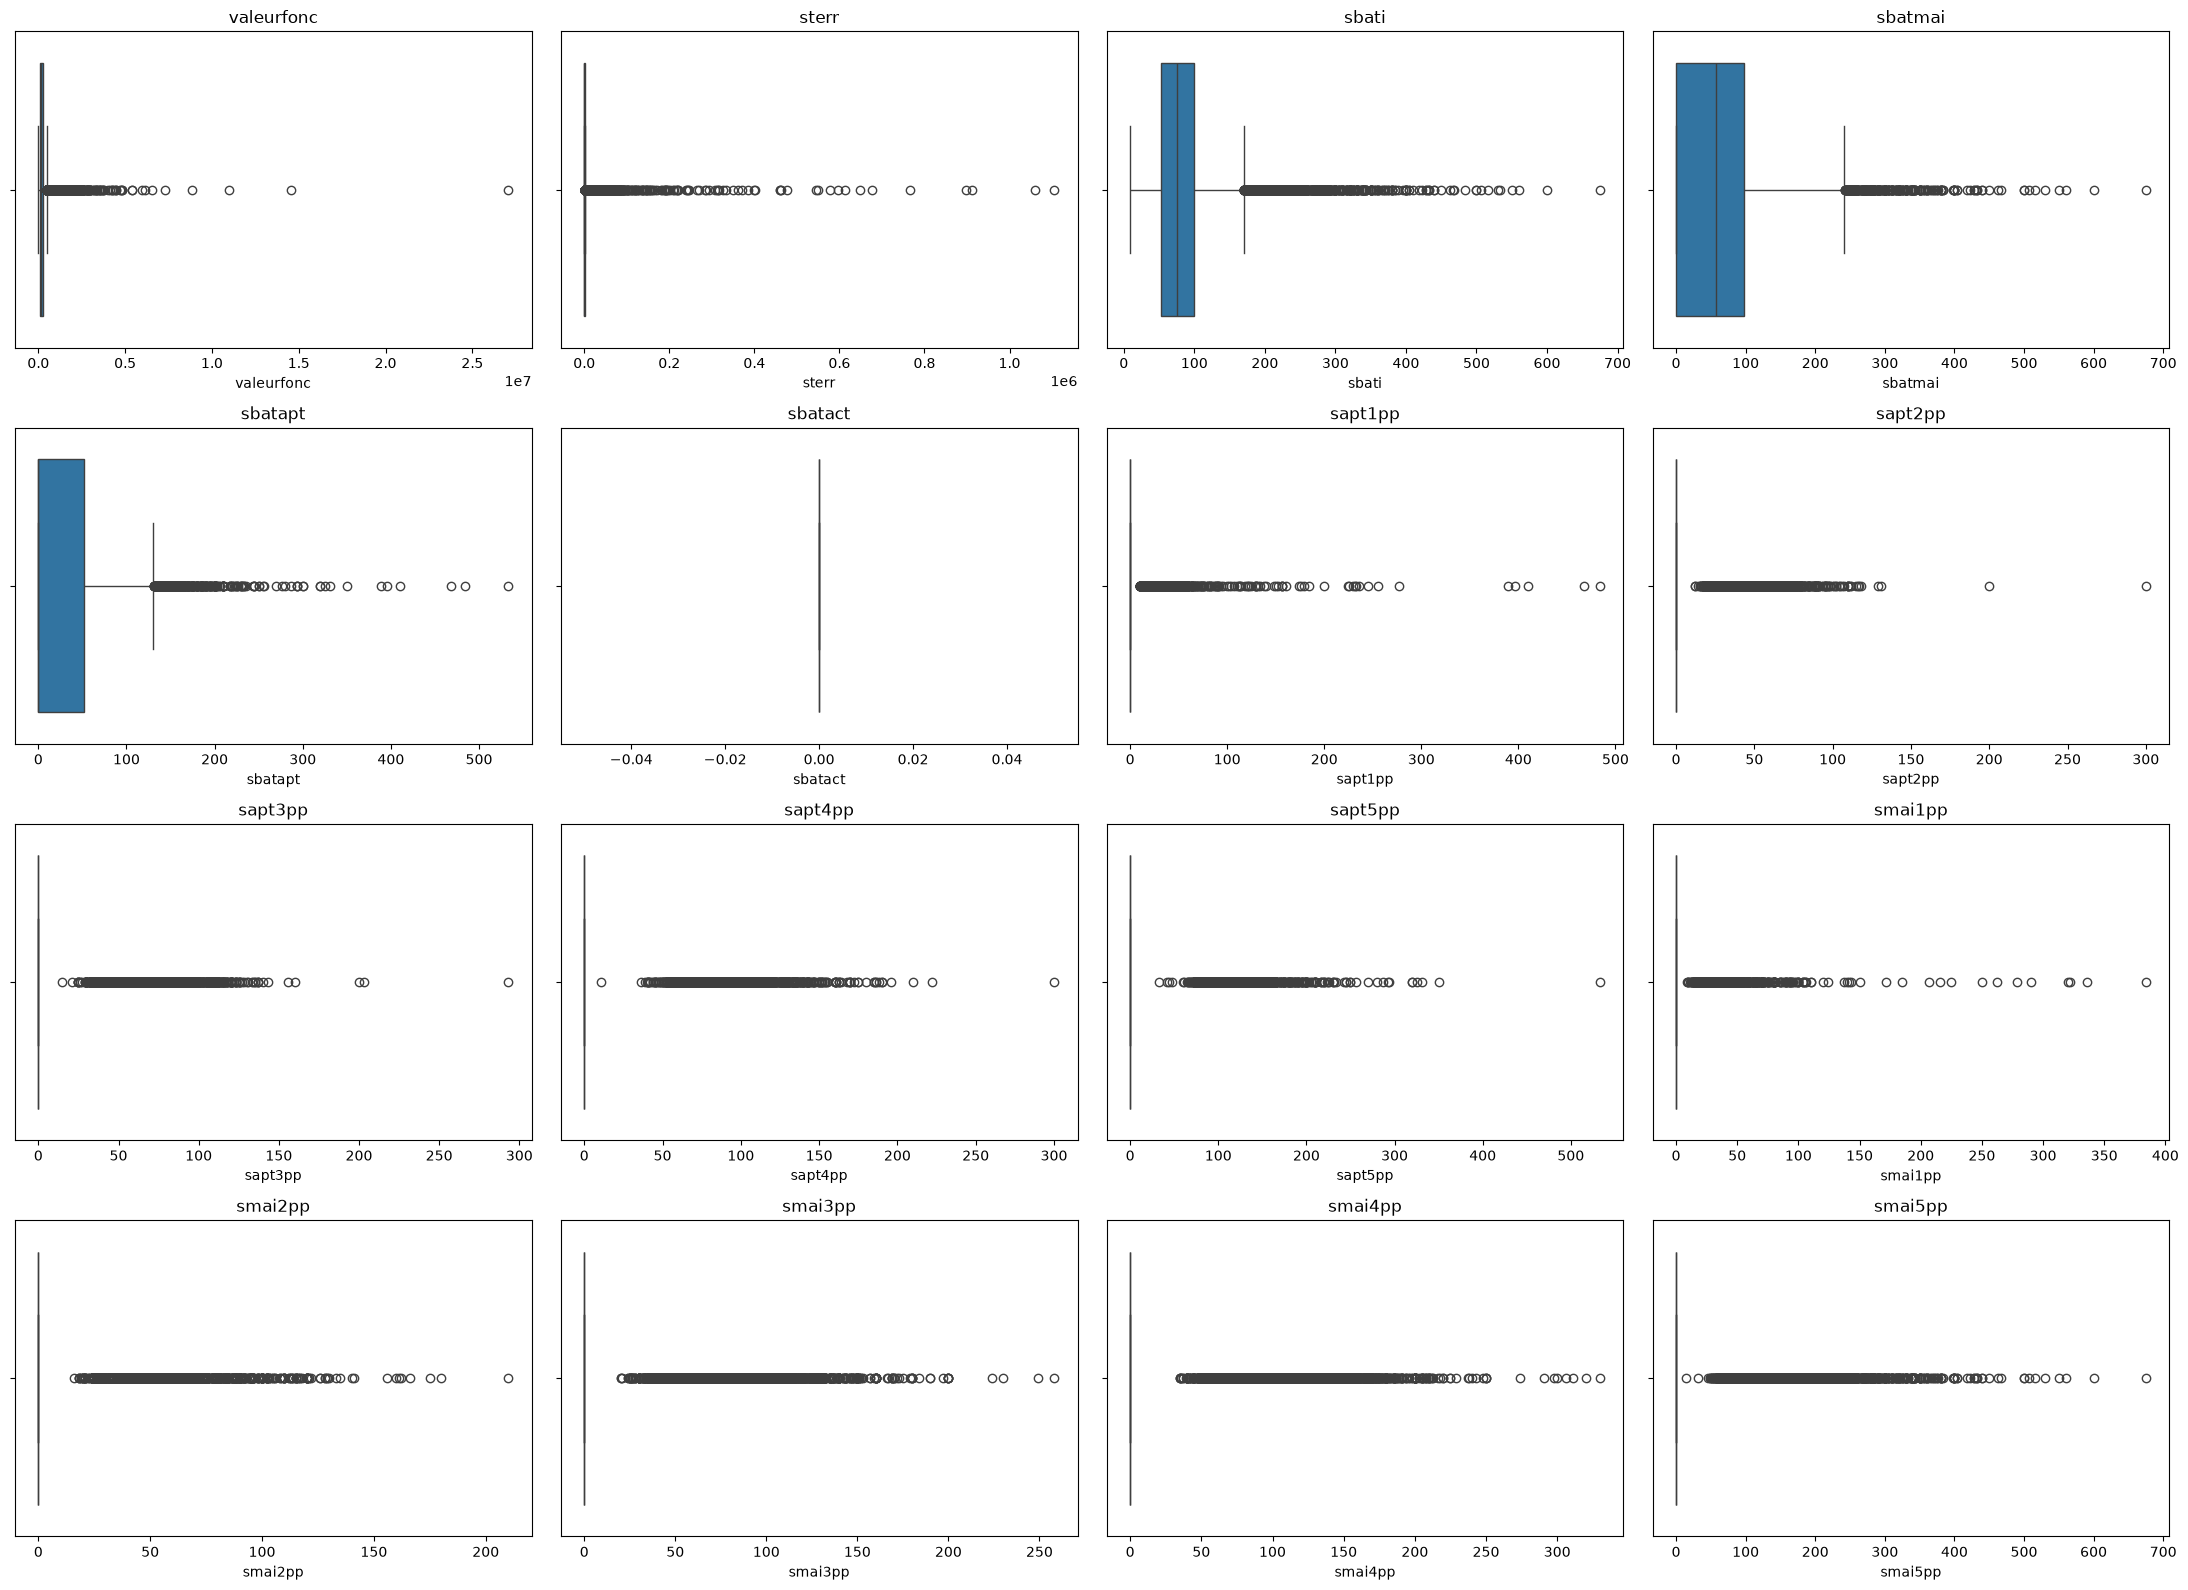

In [43]:
fig, axes = plt.subplots(4, 4, figsize=(22, 16))
axes = axes.flatten()

for i, col in enumerate(df_num_quanti.columns):
    sns.boxplot(
        data=df_num_quanti,
        x=col,
        ax=axes[i]
    )
    axes[i].set_title(col)

plt.tight_layout()
plt.show()

In [44]:
# Vérification des valeurs nulles et des valeurs extrêmes
colonnes = ["valeurfonc", "sbati", "sterr"]

for col in colonnes:
    print(f"\nVariable : {col}")
    print("Valeurs nulles :", (df_residentiel[col] == 0).sum())
    print("Minimum :", df_residentiel[col].min())
    print("Quantile 95 % :", df_residentiel[col].quantile(0.95))
    print("Quantile 99 % :", df_residentiel[col].quantile(0.99))
    print("Maximum :", df_residentiel[col].max())


Variable : valeurfonc
Valeurs nulles : 4
Minimum : 0.0
Quantile 95 % : 550014.9999999998
Quantile 99 % : 1077292.2000000007
Maximum : 27060860.0

Variable : sbati
Valeurs nulles : 0
Minimum : 9.0
Quantile 95 % : 158.0
Quantile 99 % : 222.0
Maximum : 675.0

Variable : sterr
Valeurs nulles : 28715
Minimum : 0.0
Quantile 95 % : 3392.0
Quantile 99 % : 16027.029999999984
Maximum : 1104582.0


In [45]:
pd.crosstab(
    df_residentiel["libtypbien"],
    df_residentiel["sterr"] == 0,
    normalize="index"
).mul(100).round(2)

sterr,False,True
libtypbien,,
UN APPARTEMENT,1.97,98.03
UNE MAISON,95.53,4.47


In [46]:
df_residentiel.groupby("libtypbien")["sterr"].describe(
    percentiles=[0.25, 0.50, 0.75, 0.95, 0.99]
).round(2)

,count,mean,std,min,25%,50%,75%,95%,99%,max
libtypbien,,,,,,,,,,
UN APPARTEMENT,27738.0,14.07,438.75,0.0,0.0,0.0,0.0,0.0,108.00,45371.0
UNE MAISON,34096.0,2471.67,18908.85,0.0,304.0,634.0,1315.0,5929.5,28584.65,1104582.0


**Constat :**

L'audit porte sur un sous-échantillon de **61 834 mutations résidentielles**, correspondant à des ventes d'une maison ou d'un appartement individuel.

Dans l'ensemble, les données paraissent de bonne qualité. Aucun doublon n'a été détecté et les variables sont globalement bien renseignées. La valeur foncière ne présente que 0,03 % de valeurs manquantes et les coordonnées géographiques 0,35 %.

Trois colonnes sont entièrement vides (`codservch`, `refdoc`, `l_artcgi`) et ne présentent donc aucun intérêt pour l'analyse. La variable `l_idparmut` comporte 46,43 % de valeurs manquantes, mais celles-ci correspondent exactement aux mutations pour lesquelles `nbparmut = 0`. Il ne s'agit donc pas d'une incohérence entre ces deux variables.

Les distributions numériques sont assez asymétriques, en particulier pour les valeurs foncières et les surfaces de terrain.

**Concernant les valeurs foncières**, 99 % des mutations renseignées ne dépassent pas 1,08 million d'euros, mais le maximum atteint 27,06 millions d'euros. Quatre mutations présentent également une valeur foncière nulle. Ces observations sont atypiques et mériteront d'être examinées pour déterminer s'il s'agit de transactions particulières ou d'anomalies.

**Les surfaces bâties présentent une distribution plus homogène.** Aucune valeur nulle n'a été relevée, 95 % des surfaces ne dépassent pas 158 m² et 99 % restent inférieures ou égales à 222 m². La surface maximale est de 675 m², ce qui reste plausible pour une grande propriété. Aucune anomalie manifeste ne ressort de cette première analyse.

**Pour les surfaces de terrain, l'analyse par type de logement a permis de clarifier les résultats.** Initialement, 46,44 % des mutations présentaient une surface nulle, ce qui pouvait laisser penser à un problème de qualité. En distinguant les maisons des appartements, on constate que :

- 98,03 % des appartements ont une surface de terrain nulle, ce qui est cohérent avec les ventes en copropriété, où le terrain n'est généralement pas individualisé.
- Seulement 4,47 % des maisons ont une surface de terrain nulle. Pour les autres, la surface médiane est de 634 m² et le 95e percentile atteint 5 930 m².

Les valeurs nulles de `sterr` s'expliquent donc principalement par la typologie des biens et ne constituent pas un problème généralisé de qualité. En revanche, certaines superficies restent très importantes, avec un maximum dépassant 110 hectares pour les maisons. Ces transactions devront être examinées pour vérifier leur cohérence avec le périmètre du projet.

### Conclusion et décisions

Le sous-échantillon présente une **bonne complétude, aucun doublon détecté et des distributions globalement cohérentes avec la nature des biens étudiés**. Les vérifications croisées ont notamment permis de montrer que certaines valeurs initialement suspectes, comme les surfaces de terrain nulles, s'expliquent par les caractéristiques des transactions.

Les principales réserves concernent les valeurs foncières extrêmes, les quatre transactions à valeur nulle et quelques surfaces de terrain particulièrement élevées. Il reste également à comprendre les surfaces nulles observées pour une minorité de maisons.

À ce stade, rien ne justifie un nettoyage systématique des données. Les valeurs extrêmes ne sont pas nécessairement des erreurs : elles peuvent correspondre à des transactions rares mais réelles.

**Pour la suite**, les vérifications seront concentrées sur ces quelques situations particulières. Les éventuelles décisions de traitement devront être justifiées par leur cohérence métier et leur pertinence pour le modèle de prédiction, plutôt que par leur seul caractère statistiquement atypique.

# Synthèse du premier niveau d'audit — DVF+

### Constat
La base DVF+ constitue une source pertinente pour le projet Compagnon Immo. Issue des données fiscales de la DGFiP et structurée par le Cerema, elle permet d'étudier les transactions immobilières réellement enregistrées, sur une période de 12 ans (2014–2025) et à l'échelle de 97 départements.

L'échantillon initial de 100 000 mutations a permis de mettre en évidence une forte diversité des transactions : logements individuels, terrains, locaux d'activité et opérations portant parfois sur plusieurs centaines de biens. Cette hétérogénéité rendait difficile l'évaluation de la qualité des données au regard de notre objectif métier.

Nous avons donc choisi de restreindre le périmètre aux ventes classiques et aux VEFA portant sur **une seule maison ou un seul appartement**, avec d'éventuelles dépendances. Ce premier sous-échantillonnage a permis de conserver **61 834 mutations**, soit près de 62 % de la base initiale.

L'examen de cette population montre une qualité globalement satisfaisante. Aucun doublon n'a été détecté, les variables essentielles sont très largement renseignées et les surfaces bâties présentent des distributions cohérentes avec le marché résidentiel. Les vérifications croisées ont également permis d'expliquer certaines particularités, notamment les surfaces de terrain nulles, qui concernent principalement les appartements.

Les principales réserves portent sur les valeurs foncières extrêmes, quelques transactions à valeur nulle et certaines superficies de terrain particulièrement importantes. Ces observations ne constituent pas nécessairement des erreurs, mais devront être examinées avant la modélisation.

**Ce premier audit permet donc de retenir DVF+ comme source de travail pour Compagnon Immo**, avec une limite importante : la valeur foncière est associée à une mutation et non à chaque bien pris individuellement. Le choix de travailler sur des transactions portant sur un seul logement répond notamment à cette contrainte.

### Ouverture vers d'autres sources de données

La base contient également les codes INSEE des communes concernées par chaque mutation (l_codinsee). Cette information constitue un point d'entrée intéressant pour enrichir ultérieurement les données immobilières avec des indicateurs territoriaux : population, évolution démographique, niveau de vie, services et équipements de proximité.

Ces rapprochements pourraient notamment être réalisés avec les données de l'INSEE et la Base permanente des équipements (BPE), afin d'intégrer des caractéristiques de l'environnement local dans le futur modèle de prédiction.

Il faudra toutefois tenir compte du fait que l_codinsee est une liste de codes communaux : sa structure devra être vérifiée avant toute jointure, notamment pour les mutations concernant plusieurs communes. La cohérence temporelle entre les différentes sources devra également être assurée.

### Décisions pour la suite

Le périmètre résidentiel est retenu pour poursuivre l'analyse exploratoire. Les contrôles complémentaires porteront principalement sur la cohérence des prix et des surfaces, ainsi que sur les différences entre maisons, appartements et VEFA.

La couverture temporelle et géographique du sous-échantillon devra également être examinée, afin d'identifier d'éventuels déséquilibres susceptibles d'influencer le futur modèle.

Enfin, la constitution d'un échantillon initial plus important, de l'ordre de **200 000 mutations**, reste envisagée pour augmenter le nombre de transactions résidentielles disponibles.

À ce stade, aucun nettoyage systématique n'est engagé. Les résultats de l'audit fournissent une première connaissance de la structure, du contenu et des limites de la base, suffisante pour passer à une EDA davantage orientée vers les questions métier et la préparation du modèle de prédiction.

